# pyOpenMS Isotope Distribution — Exploration

Compare pyOpenMS `CoarseIsotopePatternGenerator` against the current custom
`get_peaks_for_formula` implementation in `formula_utils.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyopenms
from pyopenms import EmpiricalFormula, CoarseIsotopePatternGenerator, FineIsotopePatternGenerator

from fragnnet.utils.formula_utils import (
    get_peaks_for_formula,
    isotope_offsets_from_formula,
    parse_formula,
)
from fragnnet.utils.spec_utils import detect_isotope_peaks_formula_aware

print('pyopenms version:', pyopenms.__version__)


torch_linear_assignment not found; falling back to scipy.optimize.linear_sum_assignment (slower, CPU-only)


pyopenms version: 3.5.0


## 1. Basic API — CoarseIsotopePatternGenerator

In [2]:
# Raw pyopenms API — this is what get_peaks_for_formula now calls internally.
ec = parse_formula('C10H14N2O5')  # thymidine
formula_str = ''.join(f'{el}{n}' for el, n in ec.items() if n > 0)
emp = EmpiricalFormula(formula_str)
gen = CoarseIsotopePatternGenerator(5)
iso = gen.run(emp)
iso.renormalize()
for p in iso.getContainer():
    if p.getIntensity() >= 0.001:
        print(f'  m/z={p.getMZ():.6f}  prob={p.getIntensity():.6f}')


  m/z=242.090273  prob=0.879222
  m/z=243.093628  prob=0.104680
  m/z=244.096983  prob=0.014739
  m/z=245.100338  prob=0.001260


## 2. Verification — `get_peaks_for_formula` now uses pyopenms

`get_peaks_for_formula` was rewritten to call `CoarseIsotopePatternGenerator` directly,
replacing the old multinomial convolution.


In [3]:
test_formulas = [
    'C6H12O6',      # glucose
    'C10H14N2O5',   # thymidine
    'C27H46O',      # cholesterol-like
    'C5H5N5',       # adenine
    'C2HCl3',       # trichloroethylene (heavy isotopes)
    'C10H8Br2',     # dibromonaphthalene (Br dominates M+2)
]

for formula in test_formulas:
    ec = parse_formula(formula)
    masses, probs = get_peaks_for_formula(ec, threshold=0.001)
    pairs = sorted(zip(masses, probs))
    print(f'{formula}: {len(pairs)} peaks  M0={pairs[0][0]:.5f}  M0_prob={pairs[0][1]:.5f}')


C6H12O6: 3 peaks  M0=180.06339  M0_prob=0.92264
C10H14N2O5: 4 peaks  M0=242.09027  M0_prob=0.87922
C27H46O: 4 peaks  M0=386.35487  M0_prob=0.74218
C5H5N5: 3 peaks  M0=135.05450  M0_prob=0.92979
C2HCl3: 5 peaks  M0=129.91438  M0_prob=0.43293
C10H8Br2: 5 peaks  M0=285.89927  M0_prob=0.23646


## 3. Isotope distribution plot


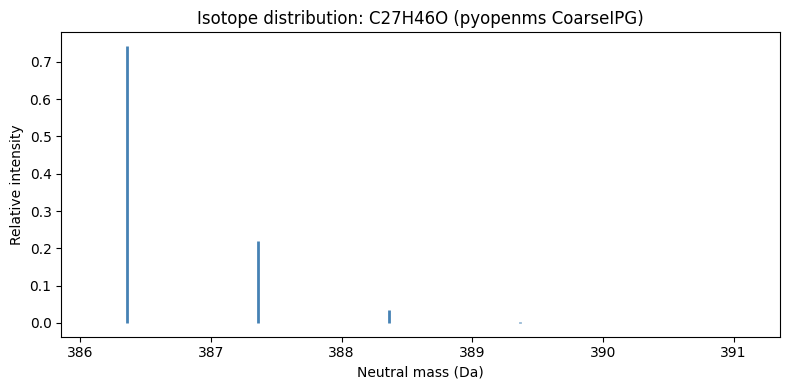

In [4]:
formula = 'C27H46O'
ec = parse_formula(formula)
masses, probs = get_peaks_for_formula(ec, threshold=0.0001)

fig, ax = plt.subplots(figsize=(8, 4))
ax.vlines(masses, 0, probs, linewidth=2, color='steelblue')
ax.set_title(f'Isotope distribution: {formula} (pyopenms CoarseIPG)')
ax.set_xlabel('Neutral mass (Da)')
ax.set_ylabel('Relative intensity')
ax.set_xlim(min(masses) - 0.5, min(masses) + 5)
plt.tight_layout()
plt.show()


## 4. Speed benchmark


In [5]:
import timeit

bench_formulas = [
    ('small  C6H12O6',      parse_formula('C6H12O6')),
    ('medium C27H46O',      parse_formula('C27H46O')),
    ('large  C50H90N10O15', parse_formula('C50H90N10O15')),
    ('halogen C10H8Br2',    parse_formula('C10H8Br2')),
]

N = 500
print(f'{"Formula":<26}  {"get_peaks_for_formula (ms)":>26}')
print('-' * 56)
for name, ec in bench_formulas:
    t = timeit.timeit(lambda: get_peaks_for_formula(ec, threshold=0.001), number=N) / N * 1000
    print(f'{name:<26}  {t:>25.3f}')


Formula                     get_peaks_for_formula (ms)
--------------------------------------------------------
small  C6H12O6                                  0.006
medium C27H46O                                  0.007
large  C50H90N10O15                             0.008
halogen C10H8Br2                                0.006


## 5. FineIsotopePatternGenerator — higher resolution

`FineIsotopePatternGenerator` resolves individual isotopologue masses (e.g. ¹³C vs ²H vs ¹⁵N contributions at M+1). Useful if we ever need sub-Da isotope spacing for FT data.

In [6]:
formula = 'C10H14N2O5'
emp = EmpiricalFormula(formula)

fine_gen = FineIsotopePatternGenerator(0.001)  # threshold on probability
fine_iso = fine_gen.run(emp)
fine_iso.renormalize()
container = fine_iso.getContainer()

print(f'FineIPG peaks for {formula} (prob >= 0.1%):')
for p in sorted(container, key=lambda x: x.getMZ()):
    if p.getIntensity() >= 0.001:
        print(f'  mass={p.getMZ():.6f}  prob={p.getIntensity():.6f}')

FineIPG peaks for C10H14N2O5 (prob >= 0.1%):
  mass=242.090273  prob=0.879888
  mass=243.087308  prob=0.006500
  mass=243.093628  prob=0.095166
  mass=243.094490  prob=0.001676
  mass=243.096550  prob=0.001417
  mass=244.094527  prob=0.009041
  mass=244.096983  prob=0.004632


## 6. `isotope_offsets_from_formula` and `detect_isotope_peaks_formula_aware`

Both are now in the library:
- `fragnnet.utils.formula_utils.isotope_offsets_from_formula`
- `fragnnet.utils.spec_utils.detect_isotope_peaks_formula_aware`


In [7]:
# isotope_offsets_from_formula and detect_isotope_peaks_formula_aware
# are now in the library — imported at the top of this notebook.

print("Isotopologue offsets for C27H46O:")
for off, rel in isotope_offsets_from_formula(parse_formula("C27H46O")):
    print(f"  M+{off:.4f} Da  rel_intensity={rel:.4f}")

print()
print("Isotopologue offsets for C10H8Br2 (Br dominates M+2):")
for off, rel in isotope_offsets_from_formula(parse_formula("C10H8Br2")):
    print(f"  M+{off:.4f} Da  rel_intensity={rel:.4f}")


Isotopologue offsets for C27H46O:
  M+1.0034 Da  rel_intensity=0.2209
  M+2.0067 Da  rel_intensity=0.0332
  M+3.0101 Da  rel_intensity=0.0034

Isotopologue offsets for C10H8Br2 (Br dominates M+2):
  M+1.0034 Da  rel_intensity=0.0258
  M+2.0067 Da  rel_intensity=0.4613
  M+3.0101 Da  rel_intensity=0.0502
  M+4.0134 Da  rel_intensity=0.2262


## 7. Formula-aware isotope peak detection

Use pyopenms to get the **exact isotopologue mass offsets** for a given formula, then detect
isotope peaks in a spectrum using those offsets instead of a fixed `NEUTRON_MASS` step.

This matters for molecules with Cl/Br where M+2 ≫ M+1, or any case where the simple
`k × 1.008665 Da` approximation drifts from the true isotopologue mass.

In [8]:
from fragnnet.utils.spec_utils import detect_isotope_peaks
from fragnnet.utils.formula_utils import NEUTRON_MASS

# Synthetic Br2 spectrum — peaks positioned at CoarseIPG offsets (k × 1.0034 Da).
# With mz_tol=0.008 Da (typical FT resolution), the naive detector (k × NEUTRON_MASS)
# searches for M+2 at mono + 2×1.008665 = mono + 2.0173, which is 0.0106 Da away
# from the actual peak (mono + 2.0067) — outside tolerance, so it is missed.
# Formula-aware uses the exact CoarseIPG offset and finds the peak correctly.
mono = 285.8936
synthetic_mzs = np.array([mono, mono + 1.0034, mono + 2.0067, mono + 3.0101, mono + 4.0134])
synthetic_ints = np.array([100.0, 5.0, 97.0, 2.0, 24.0])  # Br2 pattern

ec_br2 = parse_formula("C10H8Br2")
mz_tol = 0.008  # tight FT tolerance exposes the NEUTRON_MASS drift
mask_naive = detect_isotope_peaks(synthetic_mzs, synthetic_ints, mz_tol=mz_tol)
mask_fa    = detect_isotope_peaks_formula_aware(synthetic_mzs, synthetic_ints, ec_br2, mz_tol=mz_tol)

print("C10H8Br2 — naive vs formula-aware (mz_tol=0.008 Da)")
print(f"{'m/z':>10}  {'intensity':>10}  {'naive':>6}  {'formula-aware':>14}  note")
offsets_br2 = [0.0] + [off for off, _ in isotope_offsets_from_formula(ec_br2)]
for mz, intensity, n, fa, off in zip(synthetic_mzs, synthetic_ints, mask_naive, mask_fa, offsets_br2):
    naive_target = off * 0 + (mz - mono) / NEUTRON_MASS  # nominal k from NEUTRON_MASS
    k = round((mz - mono) / 1.0034)
    naive_err = abs((mz - mono) - k * NEUTRON_MASS)
    note = f"NEUTRON_MASS err={naive_err:.4f} Da" if k > 0 else "monoisotopic"
    print(f"{mz:>10.4f}  {intensity:>10.1f}  {str(n):>6}  {str(fa):>14}  {note}")


C10H8Br2 — naive vs formula-aware (mz_tol=0.008 Da)
       m/z   intensity   naive   formula-aware  note
  285.8936       100.0   False           False  monoisotopic
  286.8970         5.0    True            True  NEUTRON_MASS err=0.0053 Da
  287.9003        97.0   False            True  NEUTRON_MASS err=0.0106 Da
  288.9037         2.0    True            True  NEUTRON_MASS err=0.0159 Da
  289.9070        24.0   False            True  NEUTRON_MASS err=0.0213 Da
